# QE017: An Electron in a Crowd

**Quasiparticles, Mott insulators and what Green's functions really measure.**

Add one electron to a solid. It does not travel alone: it pushes and pulls on all the others, and they rearrange around
it. What moves through the material is a *dressed* electron, a **quasiparticle**. If the repulsion is strong enough,
something more dramatic happens: electrons jam, and a material that should conduct becomes an insulator, a **Mott
insulator**. That is the starting point for the physics of high-temperature superconductors.

**Green's functions** are the natural language for this. Strip away the formalism and a Green's function answers one
physical question: *if I add (or remove) an electron here, what energies does the system respond with, and how
strongly?* That answer is exactly what a photoemission experiment measures.

This exercise follows that physics through the simplest model that contains it, the **Hubbard model**:

* **Part A (one exact answer, Euler-style):** the exact Mott gap of the infinite Hubbard chain.
* **Part B1:** exact calculations on small rings approach that answer.
* **Part B2:** the spectral function: quasiparticles, their weight, and the "Hubbard bands" that appear beside them.
* **Part B3:** approximations that follow the diagrams. Second-order theory is right for weak repulsion and blind to
  the Mott gap; mean field fakes the gap by inventing magnetic order.
* **Part B4:** **embedding**: solve a small cluster exactly, then reconnect it to an infinite chain.
* **Animation:** the Mott gap opening as the repulsion grows.

### Words used in this notebook

| term | meaning |
|---|---|
| **Hubbard model** | electrons hop between neighbouring sites (strength t) and pay an energy U when two sit on the same site |
| **half filling** | one electron per site on average, where Mott physics is strongest |
| **band** | the energies $-2t\cos k$ a free electron with momentum k can have on a chain |
| **Green's function / propagator** | the amplitude that an electron added at one place and time is found at another |
| **spectral function A(k, ω)** | the probability that adding or removing an electron of momentum k costs energy ω. Photoemission (ARPES) measures it |
| **quasiparticle** | a sharp peak in A(k, ω): an electron dressed by its surroundings, still behaving like one particle |
| **quasiparticle weight Z** | the height of that peak: the fraction of the original electron that survives the dressing |
| **satellite / Hubbard band** | extra spectral weight away from the quasiparticle, created by the interactions |
| **self-energy Σ** | everything the crowd does to the electron, packed into one energy-dependent correction |
| **Dyson equation** | $G = 1/(\omega - \varepsilon_k - \Sigma)$: how the self-energy turns a free electron into a dressed one |
| **diagram** | a picture of one "story" of interaction events. The second-order diagram: the electron kicks up an electron-hole pair and later reabsorbs it |
| **mean field (Hartree–Fock)** | each electron feels only the average of the others |
| **charge gap Δ** | energy to add one electron plus energy to remove one: $E(N{+}1) + E(N{-}1) - 2E(N)$ |
| **Mott insulator** | an insulator caused by repulsion alone, not by a filled band |
| **embedding** | treat a small region exactly and the rest more simply, then stitch them together |
| **Lehmann representation** | building the Green's function from the exact eigenstates of the system |

This notebook needs `numpy`, `scipy`, `pandas` and `matplotlib` (Pillow for the GIF comes with matplotlib). It runs in
about two minutes and writes one GIF animation next to itself.

> **Report version.** This copy shows the text, results, plots and animation only. The full runnable notebook with all code is `QE017_An_Electron_in_a_Crowd.ipynb` in the same folder.

## 1. Two limits that do not fit together

$$H = -t\sum_{\langle ij\rangle,\sigma} \big(c^\dagger_{i\sigma}c_{j\sigma} + \text{h.c.}\big) + U\sum_i n_{i\uparrow}n_{i\downarrow}$$

(We set $t = 1$, so energies are in units of the hopping.)

* **No repulsion (U = 0):** electrons form a band, $\varepsilon_k = -2t\cos k$. At half filling the band is half full
  and the chain is a metal: adding or removing an electron costs nothing.
* **No hopping (t = 0):** every site holds one electron. Removing one costs nothing, but adding one makes a double
  occupancy and costs U. The spectrum is two sharp lines a distance U apart: an insulator.

The interesting physics is in between, where neither picture works. There the electron is neither a free wave nor
locked to a site.

## Part A: the exact Mott gap

In 1968 Lieb and Wu solved the one-dimensional Hubbard chain exactly. At half filling it is an insulator for *any*
$U > 0$, with charge gap

$$\Delta(U) = U - 4t + 8t\int_0^\infty \frac{J_1(x)}{x\,\big(1 + e^{xU/2t}\big)}\,dx ,$$

where $J_1$ is a Bessel function.

**Task:** compute the Mott gap for $U = 4t$ and report

$$A = \lfloor 10^6\, \Delta(4t)/t \rfloor .$$

*Check value:* $\Delta(8t) = 4.679517\ldots\,t$. For large $U$ the gap approaches $U - 4t$; for small $U$ it is
exponentially small, $\Delta \approx \frac{8t}{\pi}\sqrt{U/t}\,e^{-2\pi t/U}$.

check, U = 8: gap = 4.679517107
U = 4       : gap = 1.2867270220
limits at U = 4: large-U estimate U - 4 = 0,  small-U estimate = 1.0587

ANSWER  A = 1286727


At $U = 4t$, equal to the full bandwidth, the system sits right in the crossover: neither the small-$U$ nor the large-$U$
formula is accurate (1.06 and 0 against the true 1.29). Approximations have to work hardest here.

## Part B1: exact diagonalisation of small rings

To get beyond formulas we need the many-electron states themselves. For a ring of $L$ sites the states are lists of
which sites hold up-spin and down-spin electrons. Hopping moves one electron to a neighbouring site, with a minus
sign whenever it passes other electrons of the same spin (fermions are antisymmetric). The repulsion just counts
doubly occupied sites. We build the Hamiltonian as a sparse matrix and find its lowest energies with 0, ±1 extra
electrons. (Rings with $L = 8$ and $12$ use antiperiodic boundary conditions, so that every ring has a unique ground
state.)

sanity check, U = 0, L = 6: gap = 2.0000000000 (single-particle level spacing: 2)


computed in 26 s;  extrapolation to L → ∞: 1.113   (Lieb–Wu: 1.287)


,many-electron states (half filling),"exact gap, U = 4"
sites L,,
6,400,2.62751
8,4900,2.20496
10,63504,1.96222
12,853776,1.81092


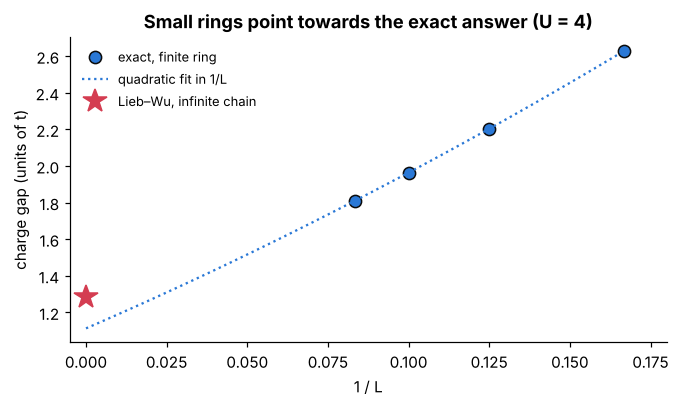

Even 853,776 many-electron states for $L = 12$ are not enough: finite rings overestimate the gap, because an electron
confined to a small ring has extra kinetic energy. A simple fit in $1/L$ moves in the right direction but goes past the
exact value (about 1.11 against 1.29), because near this crossover the finite-size corrections are not simple powers of
$1/L$. This slow, awkward convergence is why methods that reach the infinite system directly (Part B4) are valuable.

## Part B2: what a photoemission experiment would see

The **Lehmann representation** builds the Green's function from exact eigenstates. Adding an electron of momentum k
to the ground state $|0\rangle$ can leave the system in any eigenstate $|m\rangle$ of $N+1$ electrons. The spectral
function has a line at the energy cost $E_m - E_0$, with height $|\langle m|c^\dagger_k|0\rangle|^2$. Removing an
electron works the same way. For the 6-site ring there are only 300 states with one extra or one missing electron, so
we can list every line.

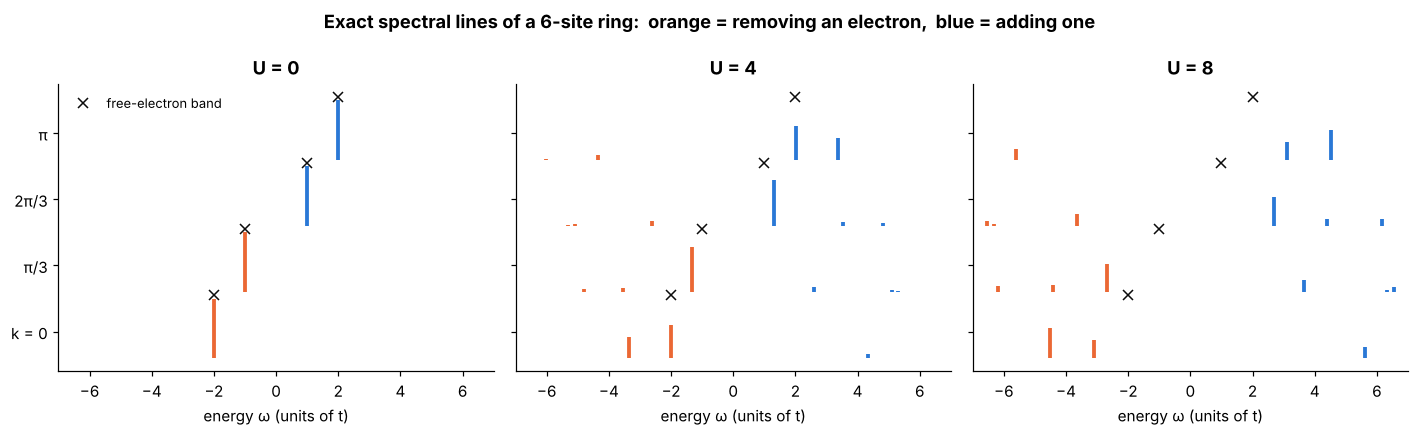

At $U = 0$ every momentum has one line of full height, sitting on the free band. As $U$ grows each line loses height
and the lost weight reappears elsewhere as smaller **satellite** lines. By $U = 8$ the weight has largely moved into two
groups separated by about $U$: the **lower and upper Hubbard bands**, the band-picture version of the atomic limit's
two lines.

The **quasiparticle weight** $Z$ measures how much of a free electron survives. We take the tallest line for
adding an electron just above the Fermi level ($k = 2\pi/3$):

U                                         0.0    0.5    1.0    2.0    3.0   4.0    6.0    8.0    10.0
quasiparticle weight Z (exact, k = 2π/3)   1.0  0.996  0.983  0.934  0.855  0.76  0.587  0.477  0.412


## Part B3: following the diagrams

Each approximation keeps some interaction "stories" and drops others. On the same 6-site ring we compare four
descriptions of the charge gap:

* **Hartree–Fock (restricted):** each electron feels only the *average* density. At half filling the average is
  uniform, so the gap stays at the free value (here 2, the level spacing of the finite ring).
* **Second-order Green's function (GF2):** keeps the second-order diagram, in which the added electron kicks up one
  electron-hole pair of opposite spin and reabsorbs it. For the Hubbard model this gives a self-energy made of discrete
  poles, $\Sigma_k(\omega) = \sum_c \frac{(U/L)^2}{\omega - E_c}$, where each configuration $c$ is an electron plus an
  electron-hole pair with total momentum $k$. The Dyson equation is then solved *exactly* by enlarging the matrix
  ("upfolding"): its eigenvalues are the poles of the dressed Green's function.
* **Unrestricted Hartree–Fock (UHF):** mean field allowed to break symmetry. It finds an up-down-up-down
  (antiferromagnetic) arrangement that opens a gap. This order is fake in one dimension: the exact ground state has
  none.
* **Exact.**

weak-repulsion test (GF2 should be exact to order U²):
  U = 0.1: exact gap - 2 = 1.391e-04,  GF2 gap - 2 = 1.389e-04
  U = 0.2: exact gap - 2 = 5.591e-04,  GF2 gap - 2 = 5.552e-04


computed in 2 s


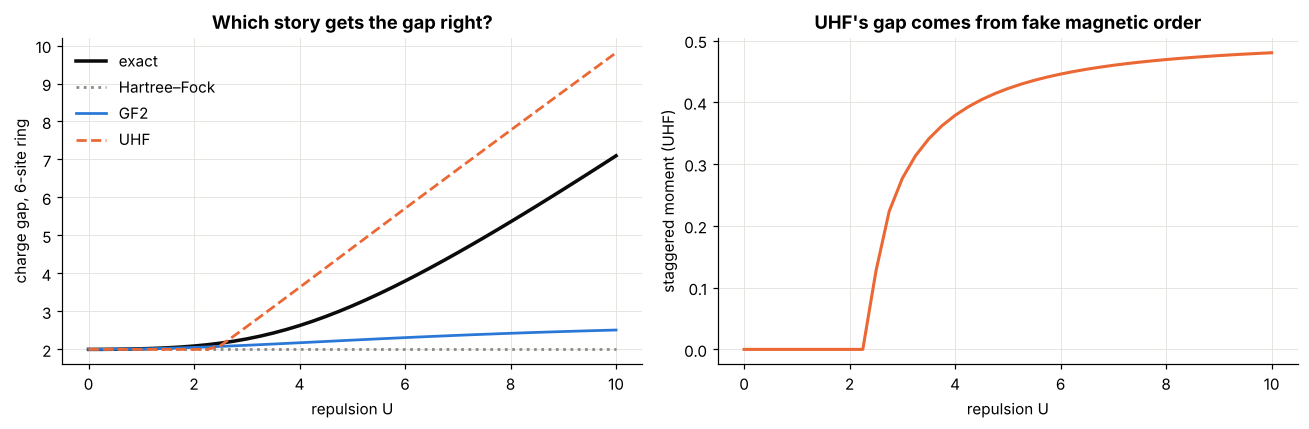

,exact,Hartree–Fock,GF2,UHF
U,,,,
1.0,2.016,2.0,2.014,2.000
2.0,2.089,2.0,2.052,2.000
4.0,2.628,2.0,2.175,3.631
6.0,3.799,2.0,2.310,5.710
8.0,5.358,2.0,2.424,7.769
10.0,7.097,2.0,2.510,9.810


The pattern is general:

* **GF2 is right where it should be.** For weak repulsion it agrees with the exact answer to order $U^2$ (the test
  above). But one electron-hole pair cannot describe an electron that is *locked out* of half the sites: the GF2 gap
  barely grows, and at $U = 8$ it is less than half the exact value.
* **UHF gets a large gap for the wrong reason.** Below a critical $U$ it finds nothing; above it, it invents
  antiferromagnetic order and overshoots, approaching $U$ instead of the true $U - 4t$ at large $U$.
* **The truth needs both**: the strong local correlation that makes the Hubbard bands, and the hopping that keeps the
  state a non-magnetic quantum liquid.

Going beyond second order, by resumming bubble chains (the GW approximation) or adding vertex corrections, is exactly
where modern Green's-function theory works. Its hardest test is the Mott gap.

## Part B4: embedding, solving a small piece exactly

**Cluster perturbation theory** is a simple embedding scheme. Cut the infinite chain into identical clusters of $L_c$
sites, solve one cluster *exactly* (Lehmann, as in B2), then reconnect the clusters through the hopping between them:

$$G(K, \omega) = \Big[\, G_\text{cluster}(\omega)^{-1} - V(K) \Big]^{-1},$$

where $V(K)$ is the hopping between neighbouring clusters. Finally we convert back to the momentum $k$ of the full chain.
It is exact at $U = 0$ (every hop is included) and at $t = 0$ (the clusters are already exact), and it gives the
spectral function of the *infinite* chain at every momentum.

exactness check at U = 0: largest deviation of the peak from -2cos k: 0.012 (grid spacing 0.024)


computed in 1 s


,cluster 2 sites,cluster 4 sites,cluster 6 sites,exact (Lieb–Wu),6-site ring (finite)
U,,,,,
2.0,0.607,0.507,0.457,0.173,2.089
4.0,2.004,1.779,1.674,1.287,2.628
6.0,3.704,3.406,3.266,2.893,3.799
8.0,5.553,5.193,5.053,4.680,5.358


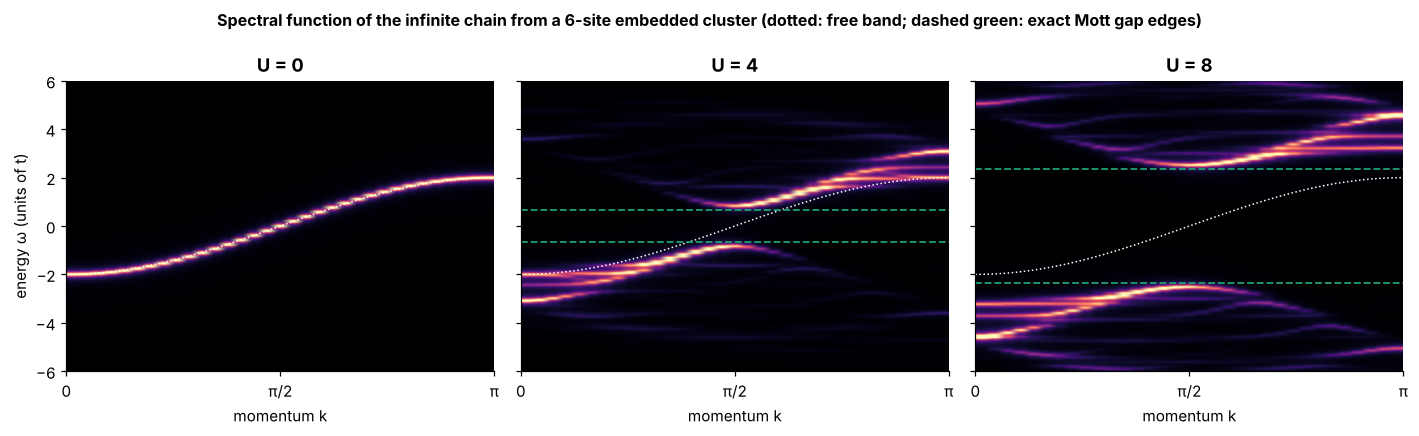

The embedded cluster gives a spectral function for every momentum of the infinite chain. As $U$ grows, the free band
splits into a lower and an upper Hubbard band, and the gap between them follows the exact Lieb–Wu edges. Bigger
clusters bring the gap closer to the exact value, the basic promise of embedding: an exact solution of a small piece,
plus a cheap description of its surroundings, can capture strong correlation that perturbation theory misses.

## Animation: the Mott gap opening

The spectral function of the infinite chain (6-site embedded cluster) as the repulsion grows from 0 to 8. Dashed lines
mark the exact Lieb–Wu gap; the right panel shows the density of states, which empties out around zero energy.

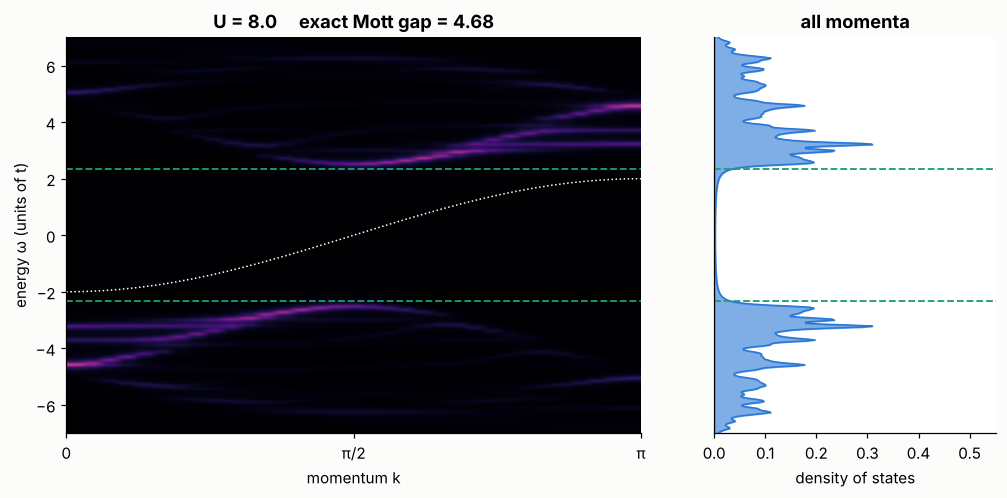

saved qe017_mott_gap.gif (9 s)


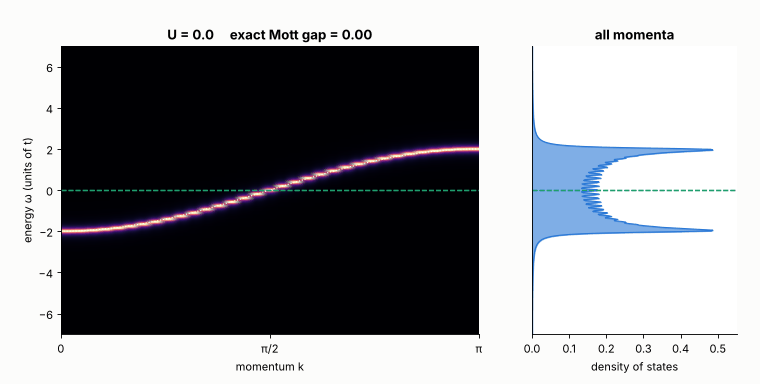

## Conclusions

1. **Exact answer.** The infinite Hubbard chain at $U = 4t$ has Mott gap $\Delta = 1.286727\ldots\,t$, so
   $A = 1286727$, from the Lieb–Wu formula.
2. **A Green's function is a measurement.** Its spectral function is what photoemission sees: quasiparticle peaks that
   lose weight as the repulsion grows, and satellites that grow into the Hubbard bands.
3. **Each approximation tells part of the story.** Second-order theory is exact for weak repulsion and blind to the
   Mott gap; symmetry-broken mean field opens a gap by inventing magnetic order.
4. **Embedding reaches the infinite system.** Solving a 6-site cluster exactly and reconnecting it captures the Hubbard
   bands and tracks the exact Mott gap far better than perturbation theory.

**Try it yourself:** add the GW approximation (resum chains of electron-hole bubbles) and see whether it opens the Mott
gap, move away from half filling (dope the Mott insulator), add a next-nearest-neighbour hopping, or make the embedding
self-consistent.

### Further reading

* E. H. Lieb, F. Y. Wu, *Absence of Mott transition in an exact solution of the short-range, one-band model in one
  dimension*, Phys. Rev. Lett. 20, 1445 (1968).
* L. Hedin, *New method for calculating the one-particle Green's function with application to the electron-gas
  problem*, Phys. Rev. 139, A796 (1965).
* D. Sénéchal, D. Perez, M. Pioro-Ladrière, *Spectral weight of the Hubbard model through cluster perturbation theory*,
  Phys. Rev. Lett. 84, 522 (2000).
* R. M. Martin, L. Reining, D. M. Ceperley, *Interacting Electrons: Theory and Computational Approaches*, Cambridge
  University Press (2016).
* J. Krieger, J. Tölle, *Renormalization group approach to second-order Green's function theory*, arXiv:2512.11410
  (2025).
* J. Tölle, M.-P. Kitsaras, A. Irmler, A. Grüneis, P.-F. Loos, *Connection between GW and extended coupled cluster*,
  arXiv:2602.10887 (2026).